In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add the project root to the PYTHONPATH
script_dir = os.getcwd()
project_root = os.path.abspath(os.path.join(script_dir, '..'))
sys.path.append(project_root)

from src.data import load_and_preprocess_data as get_data
from src.models import WorkingMemoryNetwork, balloon_windkessel_A, balloon_windkessel_B
from config.WM_params import WorkingMemoryParameters
import time
np.set_printoptions(threshold=np.inf)

/home/rad216/PhD_Projects/WM_human_merged/models/model_autoradiography_nmda_ampa/src/models.py:438: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 2, 'C', False, aligned=True), Array(float64, 1, 'A', False, aligned=True))
  dY, I_mon = calc_dY(A=A, B=B, D=D,


Elapsed (after compilation) = 10.471835880976869s
Nodes where population B is persistent: []
There is spontaneous switch to higher state: False, in populations []
[('r_A', [11, 15, 16, 19, 20, 21, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 34, 37, 38, 40, 41, 42, 43, 44, 45, 46, 47])]
Number of persistent areas: 27
Areas persistent: ['SomMot_3', 'DorsAttn_Post_1', 'DorsAttn_Post_2', 'DorsAttn_Post_5', 'DorsAttn_Post_6', 'DorsAttn_PrCv_1', 'SalVentAttn_ParOper_1', 'SalVentAttn_FrOperIns_1', 'SalVentAttn_FrOperIns_2', 'SalVentAttn_PFCl_1', 'SalVentAttn_Med_1', 'SalVentAttn_Med_2', 'SalVentAttn_Med_3', 'Limbic_OFC_1', 'Limbic_TempPole_1', 'Limbic_TempPole_2', 'Cont_PFCl_1', 'Default_Temp_1', 'Default_Temp_2', 'Default_Par_2', 'Default_PFC_1', 'Default_PFC_2', 'Default_PFC_3', 'Default_PFC_4', 'Default_PFC_5', 'Default_PFC_6', 'Default_PFC_7']


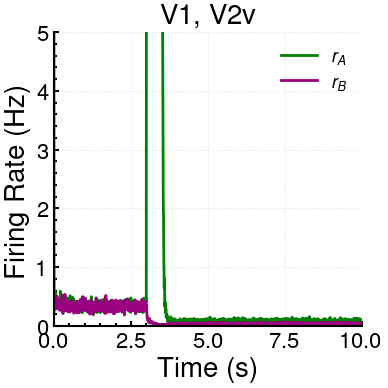

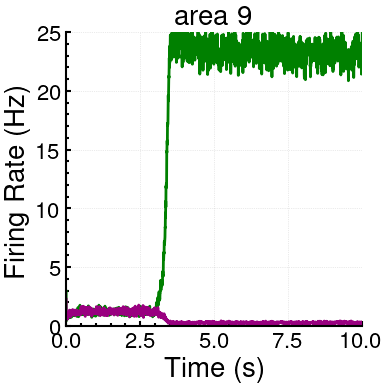

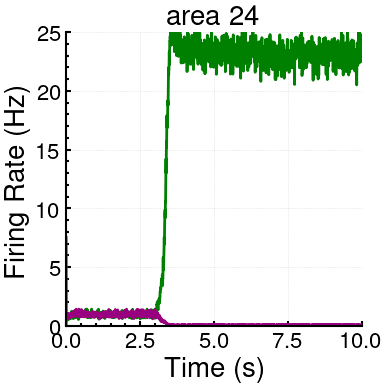

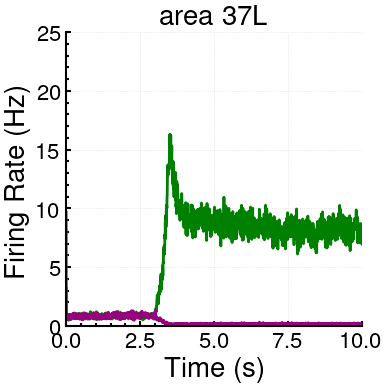

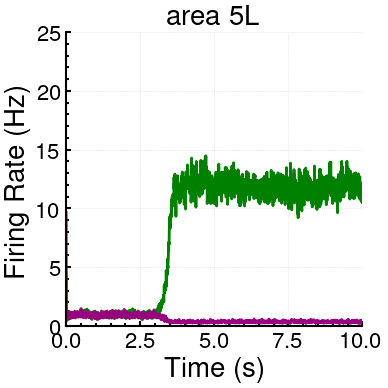

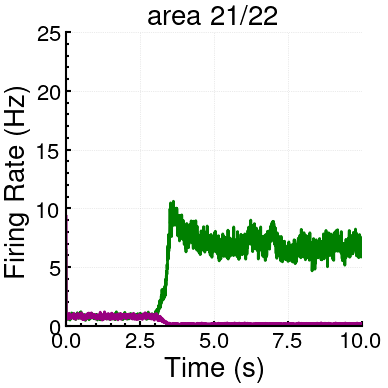

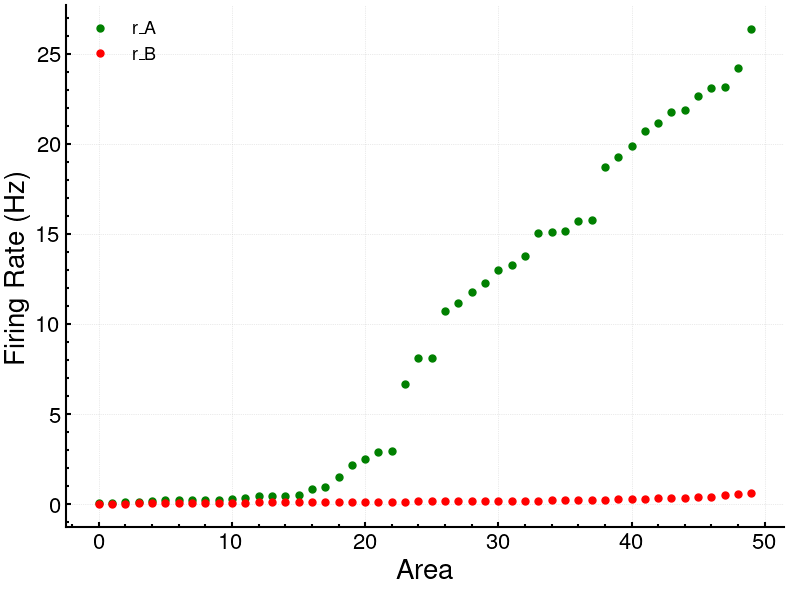

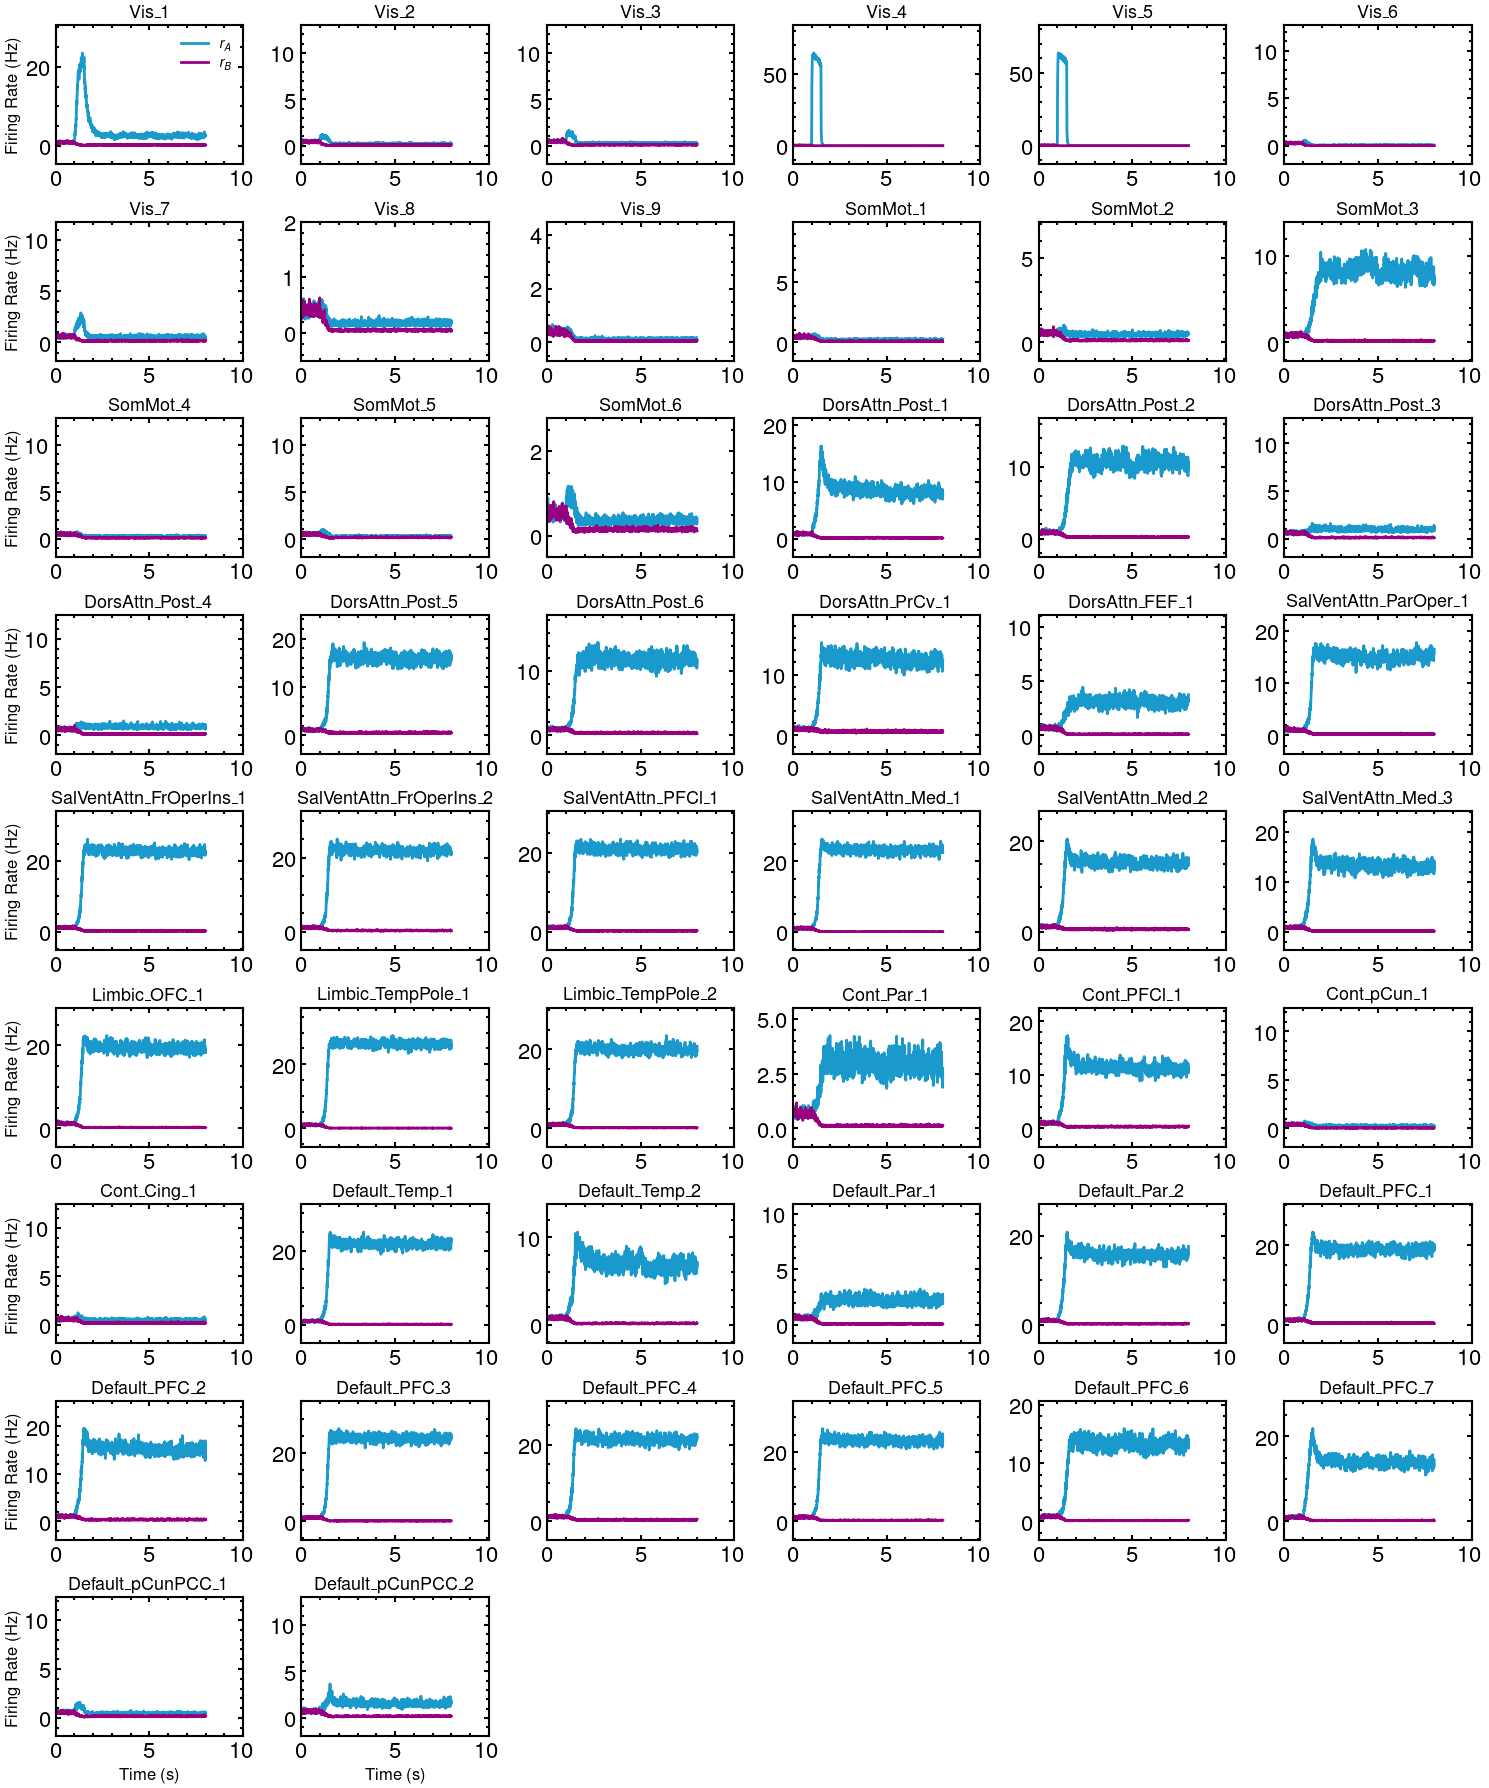

In [4]:
data_activation_maps = True # Turn True if we need data to plot cue and delay activation maps
random_seed = 666
outside_rng = np.random.default_rng(random_seed)

data = get_data(data_folder_path='../../../data/processed', parcellation='schaefer100')
area_names = data['area_names']
SLN = data['SLN']
W = data['W']
h = data['hier_vals']
normalized_nmda_rd = data['nmda_rd'] # NMDA receptor density based on autoradiography
normalized_ampa_rd = data['ampa_rd'] # AMPA receptor density based on autoradiography

# Initial condition and parameters
N = len(area_names)
Y0 = np.zeros((N, 10))
Y0[:, 0:3] = 5 * (1 + np.tanh(outside_rng.normal(0, 2, (N, 3)))) # r values are initialized randomly between 0 and 10
WM_params = WorkingMemoryParameters()
WM_params.update(G=0.58, ALPHA=1.34, J_MAX=0.3) # Update G and alpha to optimal settings
# Generate the network
WM_network = WorkingMemoryNetwork(area_names=area_names, Y0=Y0, W=W, F=SLN, h=h,
                                  normalized_nmda_rd=normalized_nmda_rd,
                                  normalized_ampa_rd=normalized_ampa_rd,
                                  params=WM_params, gradient='NMDA')
# Run the simulation
t_end = 10
dt = 0.5e-3
stim_start_time = 3
stim_duration = 0.5
t_eval = np.arange(0, t_end+dt, dt) # Time points of the simulation
I_ext_strength = np.zeros((N, 3))
I_ext_strength_distractor = np.zeros((N, 3))

# Target names for which we want to assign 0.3
target_names = ['Vis_4', 'Vis_5']
# Find indexes of the target names in the list
rows = np.where(np.isin(area_names, target_names))[0]
I_ext_strength[rows, 0] = 0.3

start = time.perf_counter()
state_history, input_history = WM_network.run(t_end=t_end, dt=dt, I_ext_strengths=np.stack([I_ext_strength]),
                               ts_ext_start=np.array([stim_start_time]),
                               ts_ext_end=np.array([stim_start_time + stim_duration]))
end = time.perf_counter()
print("Elapsed (after compilation) = {}s".format((end - start)))
avg_firing_rates_A, avg_firing_rates_B = WM_network.save_avg_firing_rates_last_two_seconds(variables=['r_A', 'r_B'])
if data_activation_maps:
    state_history_extract = WM_network.get_state_histories(['r_A'])[-1]
    np.save('../results/firing_rates_from_notebook_sim/cue_FR.npy', state_history_extract[int(stim_start_time / dt) + 100, :, 0])
    avg_firing_rates = WM_network.save_avg_firing_rates_last_two_seconds()
    np.save('../results/firing_rates_from_notebook_sim/delay_FR.npy', avg_firing_rates)

_, pops = WM_network.check_sustained_activity_after_stim_removal()

# Need condition to check if it's A or B there, right now r_B is at index 0, it gets pops_A as pops_B.
try:
    pops_A = pops[0][1]
except:
    pops_A = []
try:
    pops_B = pops[1][1]
except:
    pops_B = []

print('Nodes where population B is persistent:', pops_B)
spont_switch, pop_switch = WM_network.check_spontaneous_switch_to_high_state(stim_start_time)
print(f'There is spontaneous switch to higher state: {spont_switch}, in populations {pop_switch}')
changes_detected, changed_populations = WM_network.check_sustained_activity_after_stim_removal()
print(changed_populations)
try:
    print('Number of persistent areas:', len(changed_populations[0][1]))
    areas_persistent = [area_names[i] for i in changed_populations[0][1]]
    print('Areas persistent:', areas_persistent)
except:
    print('No persistent areas')
    
state_history_extract = WM_network.get_state_histories(['r_A'])[-1].squeeze()

# Plot the results
area_names_for_figure = ['V1, V2v', 'area 9', 'area 24', 'area 37L', 'area 5L', 'area 21/22']
_ = WM_network.plot_n_areas(xlim=(0, t_end), ylim=(0, 5),
                            target_area_names=['Vis_4', 'Default_PFC_5', 'SalVentAttn_Med_1',
                                               'DorsAttn_Post_1', 'DorsAttn_Post_6', 'Default_Temp_2'],
                            names_for_figures=area_names_for_figure,
                            variables=['r_A', 'r_B'], colors=['green', [.6, 0, .5]])
_ = WM_network.plot_avg_firing_rates_last_two_seconds()
_ = WM_network.plot_all_areas(xlim=(0, t_end), variables=['r_A', 'r_B'])